# GO Analysis for WGCNA
## Phase 2 

Gene ontology of modules from [WGCNA](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase2_v_phase2/new_refGenome/wgcna/wgcna_p1.ipynb) using the [new reference genome](https://www.ncbi.nlm.nih.gov/datasets/genome/GCF_053477285.1/). Following [Gurr code](https://github.com/SamGurr/Pgenerosa_OA_TagSeq/blob/main/TagSeq/Analysis/Scripts/GO_Analysis_WGCNA_all.R)

Since we don't have log fold change (because we aren't looking at differential expression), we can only do an over-representation analysis (ORA) - provide a gene list of interest (genes in a significantly correlated module) and a universal gene list (after filtering for wgcna - so *not* all genes in the CV genome, but rather what went in as input to wgcna)

## 0. load libraries

In [2]:
library(tidyverse)
library(goseq)
library(reshape2)
library(Rmisc)
library(ggpubr)
library(gridExtra)
library(forcats)
library(zoo)
library(ComplexHeatmap)
library(GO.db)
library(GSEABase)
library(clusterProfiler)

## 1. load data
WGCNA module membership, module colors, and goslim_generic.obo

#### A. gene annotation to GO.term - long format
matches GO terms to *C. virginica* genes - one GO term per row (so genes are duplicated among rows)

In [3]:
annot <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/annotations/newRef_geneGO.csv')
colnames(annot)[1] <- 'Gene'
colnames(annot)[2] <- 'GO.terms'

# One row for each gene and GO.term
term2gene <- annot %>%
  separate_rows(GO.terms, sep = ";") %>% # one row for each GO.term
  filter(!is.na(GO.terms) & GO.terms != "") %>% # remove genes without GO terms
  dplyr::select(term = GO.terms, gene = Gene) # rename columns for GO 

# 

head(term2gene)

term,gene
<chr>,<chr>
GO:0005261,LOC111099029
GO:0005886,LOC111099029
GO:0030001,LOC111099029
GO:0098655,LOC111099029
GO:0004930,LOC111099032
GO:0005886,LOC111099032


this becomes input for `enricher` down below

get term names for GO IDs

In [4]:
# Extract GO term descriptions
go_terms <- unique(term2gene$term)

# Get descriptions from GO.db
term2name <- data.frame(
  term = go_terms,
  name = sapply(go_terms, function(x) {
    tryCatch({
      Term(GOTERM[[x]])
    }, error = function(e) {
      NA_character_
    })
  })
)

# Remove NAs
term2name <- term2name[!is.na(term2name$name), ]

# View
head(term2name)    

,term,name
,<chr>,<chr>
GO:0005261,GO:0005261,monoatomic cation channel activity
GO:0005886,GO:0005886,plasma membrane
GO:0030001,GO:0030001,metal ion transport
GO:0098655,GO:0098655,monoatomic cation transmembrane transport
GO:0004930,GO:0004930,G protein-coupled receptor activity
GO:0007186,GO:0007186,G protein-coupled receptor signaling pathway


#### B. GOslim data

GO Slim - higher level of GO used to summarize GO results into broader categories (the parent terms)

In [5]:
slim <- getOBOCollection("http://current.geneontology.org/ontology/subsets/goslim_generic.obo")
class(slim)

[1] "OBOCollection"
attr(,"package")
[1] "GSEABase"

In [6]:
# 1. Get the GO IDs
slim_ids <- ids(slim)

# 2. Get the IDs that belong to the generic subset
slim_ids <- ids(slim["goslim_generic" ])

# 3. Get the terms for those specific IDs
# use the GO.db package because it's much faster and more reliable for names
slim_terms <- Term(slim_ids)

# 4. Create lookup table 
slim_lookup <- data.frame(
  SlimID = names(slim_terms), # parent ID
  GOSlim_Bin = as.character(slim_terms), # biological term
  stringsAsFactors = FALSE
)

head(slim_lookup)

,SlimID,GOSlim_Bin
,<chr>,<chr>
1,GO:0000228,nuclear chromosome
2,GO:0000278,mitotic cell cycle
3,GO:0000910,cytokinesis
4,GO:0001618,virus receptor activity
5,GO:0002181,cytoplasmic translation
6,GO:0002376,immune system process


this table can be used to assign GO terms to broader categories - however, this table only contains parent terms (SlimID), so cannot directly be merged with GO results - need to match the parent terms to the GO IDs

In [7]:
# 1. Get a list of all ancestors for every GO term in WGCNA results
# This creates a mapping of Specific_ID -> All_Ancestors
all_ancestors <- as.list(GOBPANCESTOR)

# lookup vector - parent GO terms
target_slim_ids <- unique(slim_lookup$SlimID)

# 2. make lookup function
find_slim_parent <- function(specific_id, slim_ids) {
  if (is.na(specific_id)) return(NA_character_) # if GO term isn't in ancestor lookup
  if (specific_id %in% slim_ids) return(specific_id) # if GO term is the parent term
  
  # Get ancestors from the GO.db object
  ancestors <- all_ancestors[[specific_id]]
  
  if (is.null(ancestors)) return(NA_character_) # if no ancestor term
  
  # Find which ancestors are in your Slim list
  match <- intersect(ancestors, slim_ids)
  
  if (length(match) == 0) return(NA_character_)
  return(as.character(match[1])) 
}


#### C. Gene info
read in gene info from [wgcna_p2.ipynb](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase2_v_phase2/wgcna/wgcna_p2.ipynb)

contains the gene name, matching GO terms, module color, gene significance (GS) for every treatment, and module membership (MM) for each module

In [19]:
geneInfo <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/wgcna/outputs/p1.wgcna_GeneInfo.csv') 
head(geneInfo) 

,Gene,ModuleColor,GS.Actual_shell_growth_mg,GS.Actual_tissue_growth_mg,GS.Ratio_tissue_shell_mg,GS.P1_trtmt_code,GS.P1_temp_code,GS.P1_DO_code,GS.both,GS.control,⋯,MMred,MMmagenta,MMtan,MMsalmon,MMpink,MMyellow,MMturquoise,MMgreenyellow,MMblue,MMgreen
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621269,turquoise,0.27424682,0.3582791,0.29229514,-0.14920643,-0.21448305,-0.05651520,-0.26455992,0.05977491,⋯,-0.33803934,0.03903579,0.08308137,-0.6663586,-0.4774152,-0.3366910,0.91160703,0.2427585,-0.01147176,-0.23949648
2,LOC111120925,black,-0.04294156,-0.1084639,-0.17545500,-0.40110317,-0.52242653,-0.17900462,-0.34668741,0.47228699,⋯,0.03494228,-0.17472145,-0.03591849,-0.0605357,-0.5535253,-0.3865442,0.20708515,0.2381314,-0.34905965,-0.16035684
3,LOC144621276,greenyellow,0.32878398,0.3863810,0.24985077,0.08277505,0.10617493,0.03775963,-0.01244986,-0.17543356,⋯,-0.54564066,0.19937653,0.03127251,-0.3251907,-0.4088393,-0.7673879,0.32804341,0.8344366,0.14248051,0.39991437
4,LOC111115920,pink,-0.18930411,-0.4664009,-0.46872840,0.51924356,0.30512331,0.41731743,0.64155708,-0.21920553,⋯,0.13257737,0.09480327,-0.14794939,0.2486783,0.5597128,0.5349486,-0.37122573,-0.2599503,0.14344611,0.06258228
5,LOC144621308,blue,0.08907557,0.1551399,0.09877676,-0.05175412,-0.00699142,-0.05330536,-0.17132811,-0.09234155,⋯,-0.14568006,-0.11875312,-0.20715449,-0.3339040,-0.3451142,-0.2124561,0.04698062,0.2494725,0.22268048,0.01317111
6,LOC111112629,greenyellow,0.17315594,0.1207242,0.01690143,0.27494455,0.17665383,0.21342964,0.08257236,-0.36619296,⋯,-0.34920839,0.23797720,0.02207314,-0.1922233,-0.0373164,-0.2711457,-0.03312545,0.4332788,0.20425568,0.30373935


categorize gene info columns

In [20]:
# Get all column names once
all_cols <- names(geneInfo)

# 1. The 16 'Combo_treatments.GS' columns
combo_cols <- grep("^Combo_treatments\\.GS\\.", all_cols, value = TRUE)

# 2. Phase 1 & 2 Driver columns (Temp and DO)
p1_driver_cols <- grep("^phase1_(temp|DO)\\.GS\\.", all_cols, value = TRUE)
p2_driver_cols <- grep("^phase2_(temp|DO)\\.GS\\.", all_cols, value = TRUE)

# 3. Overall Phase Treatment columns
p1_overall_cols <- grep("^phase1_treatment\\.GS\\.", all_cols, value = TRUE)
p2_overall_cols <- grep("^phase2_treatment\\.GS\\.", all_cols, value = TRUE)

# 4. Module Membership (MM) colors
mm_cols <- grep("^MM", all_cols, value = TRUE)

#### Module membership
pull out just the genes, associated GO terms, and which module they're been assigned to

In [21]:
moduleMembership <-  geneInfo %>% dplyr::select(Gene, ModuleColor) # select for genes, GO.ids, modules
head(moduleMembership)

,Gene,ModuleColor
,<chr>,<chr>
1,LOC144621269,turquoise
2,LOC111120925,black
3,LOC144621276,greenyellow
4,LOC111115920,pink
5,LOC144621308,blue
6,LOC111112629,greenyellow


#### D. universal list
this is the input gene list for wgcna before module assignment, but after gene filtering

In [23]:
universal_genes <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/wgcna/outputs/p1.wgcna_UniversalGeneList.csv')
colnames(universal_genes) <- 'gene'
head(universal_genes)

,gene
,<chr>
1,LOC144621269
2,LOC111120925
3,LOC144621276
4,LOC111115920
5,LOC144621308
6,LOC111112629


## 2. run GO enrichment
over-representation analysis

**input data:**
- universal_genes
- term2gene (matches gene LOC to GO term)
- term2name (matches GO term to GO description)
- geneInfo (output from WGCNA)

slim_lookup for matching parent GO terms to GO results

### red module
neg. corr. with shell growth

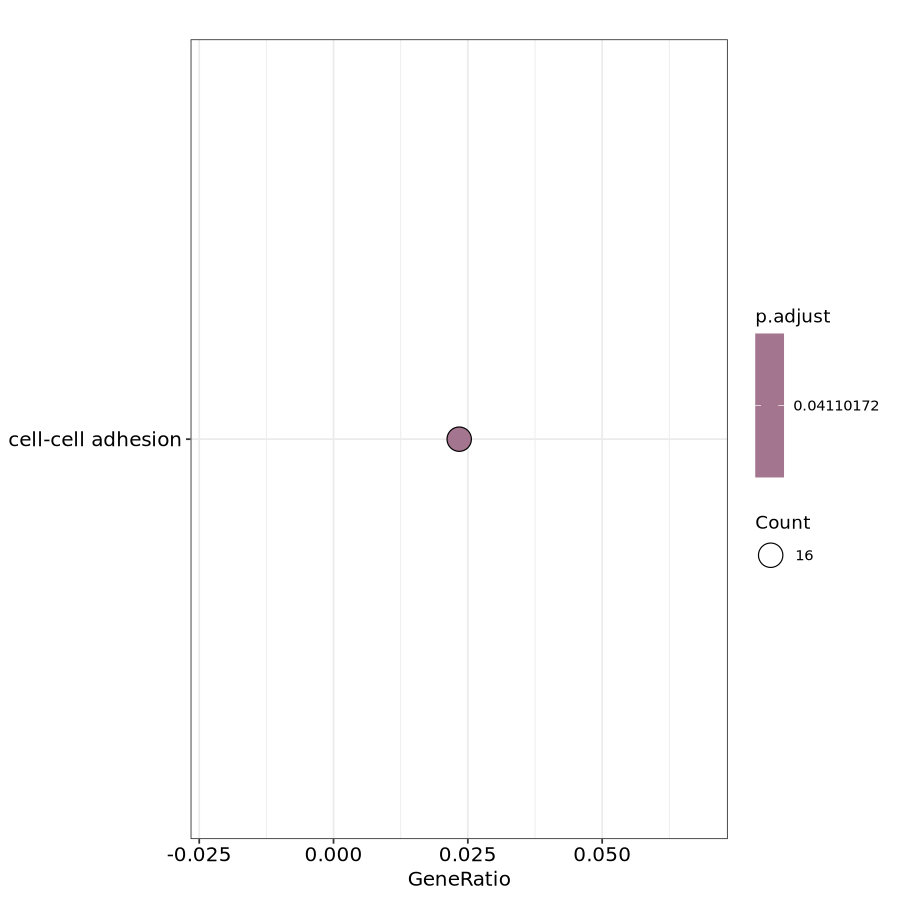

In [26]:
options(repr.plot.height = 7.5, repr.plot.width = 7.5)

# red 
target_genes <- geneInfo %>%
  filter(ModuleColor == "red") %>%
  pull(Gene)

# Run the custom enrichment
ego_custom <- enricher(gene = target_genes,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
red_res <- as.data.frame(ego_custom)

dotplot(ego_custom)

### blue module
pos. corr. with shell growth and warm treatment (as a binary treatment aka. warm vs. everything else)

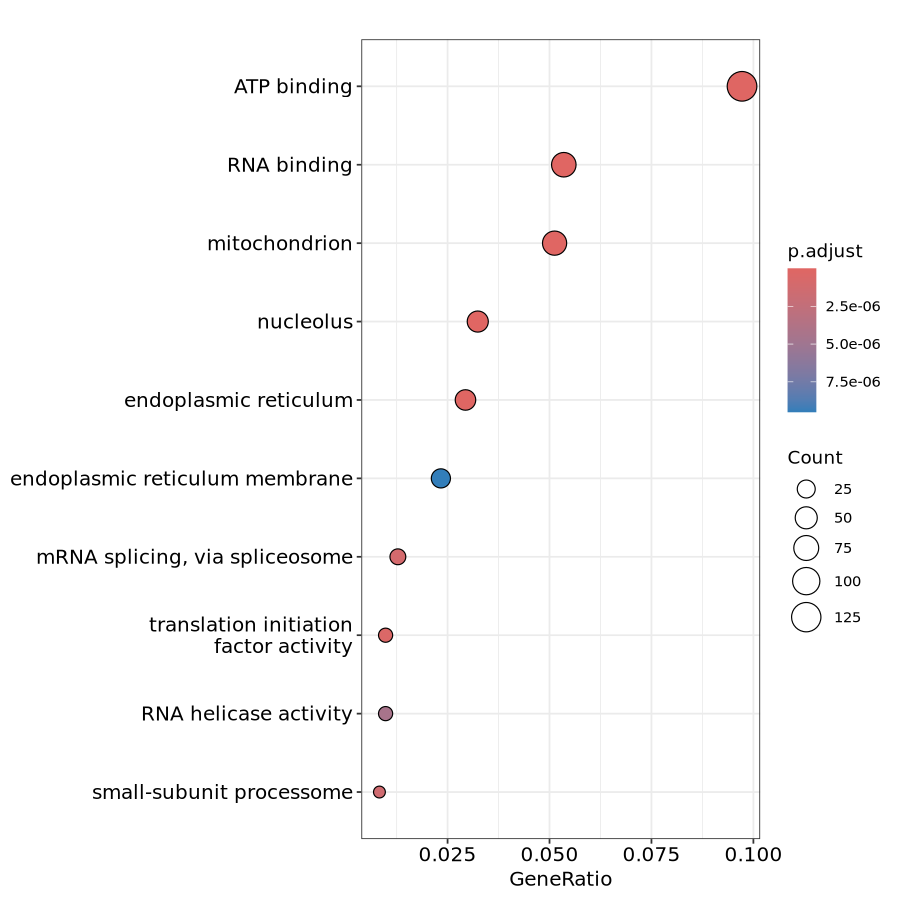

In [27]:
target_genes <- geneInfo %>%
  filter(ModuleColor == "blue") %>%
  pull(Gene)

# Run the custom enrichment
ego_custom <- enricher(gene = target_genes,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
blue_res <- as.data.frame(ego_custom)

# View results
dotplot(ego_custom)

### black module
neg. corr. with phase 1 temperature (so warming vs. ambient)

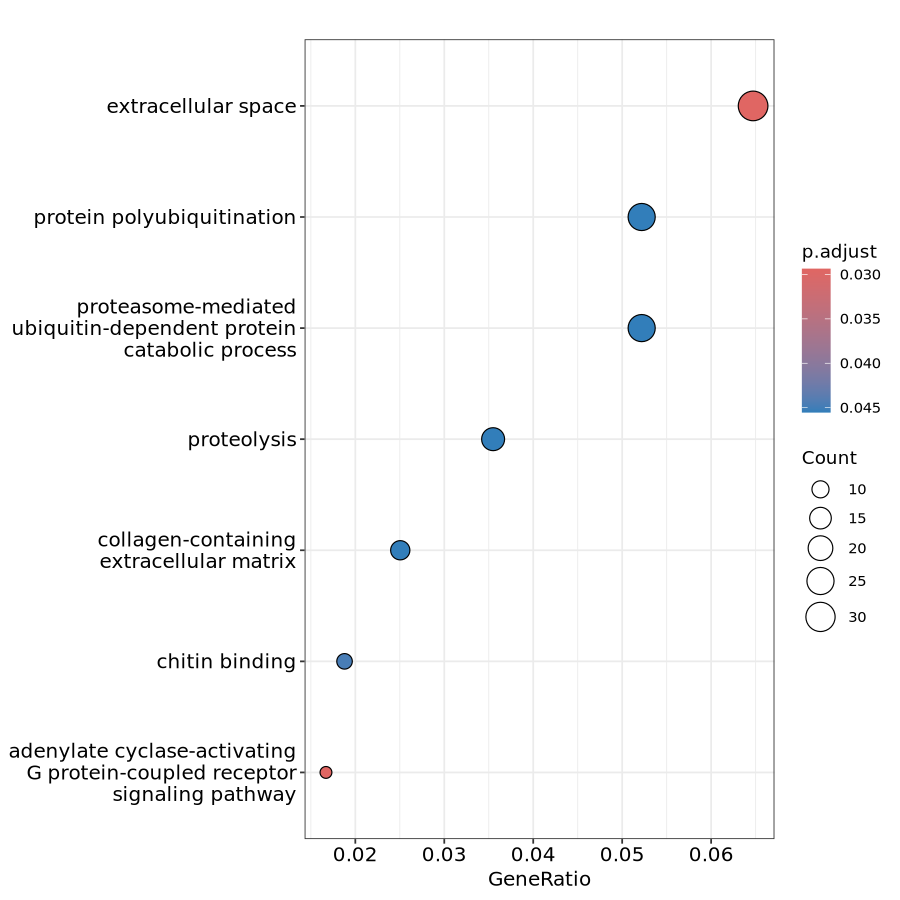

In [29]:
target_genes <- geneInfo %>%
  filter(ModuleColor == "black") %>%
  pull(Gene)

# Run the custom enrichment
ego_custom <- enricher(gene = target_genes,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
black_res <- as.data.frame(ego_custom)

dotplot(ego_custom)

### salmon module
neg. corr. with shell growth

In [30]:
target_genes <- geneInfo %>%
  filter(ModuleColor == "salmon") %>%
  pull(Gene)

# Run the custom enrichment
ego_custom <- enricher(gene = target_genes,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
salmon_res <- as.data.frame(ego_custom)
salmon_res

ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>


no enriched GO terms

## combining these:

In [31]:
blue.mod <- blue_res %>% mutate(module = 'blue')
red.mod <- red_res %>% mutate(module = 'red')
black.mod <- black_res %>% mutate(module = 'black')

mod.all <- rbind(blue.mod, red.mod, black.mod)
head(mod.all)

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,module
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
GO:0005730,GO:0005730,nucleolus,43/1327,51/7744,9.906095e-26,3.130326e-23,2.731997e-23,LOC111103620/LOC111103629/LOC111104266/LOC111104419/LOC111105256/LOC111103978/LOC111125438/LOC111123381/LOC111113203/LOC111099808/LOC111127822/LOC111132803/LOC111105066/LOC111118739/LOC111110332/LOC111136243/LOC111133059/LOC111135974/LOC111133926/LOC144626880/LOC111136414/LOC111135538/LOC111135726/LOC111134594/LOC111138243/LOC111135552/LOC111136220/LOC111133335/LOC111135565/LOC111135336/LOC111132132/LOC111134754/LOC111129891/LOC111130503/LOC111127734/LOC111130371/LOC111120892/LOC111121751/LOC111121130/LOC111118852/LOC111120775/LOC111118069/LOC111112939,43,blue
GO:0003723,GO:0003723,RNA binding,71/1327,165/7744,2.950963e-15,4.662522e-13,4.069223e-13,LOC144622099/LOC111105256/LOC144623848/LOC111104149/LOC111099922/LOC144617720/LOC144618962/LOC144618954/LOC144619035/LOC111123381/LOC144622290/LOC111127420/LOC111126771/LOC111125036/LOC111111061/LOC111113059/LOC111118963/LOC144625294/LOC111116966/LOC144625443/LOC111107584/LOC111118739/LOC111113115/LOC144625869/LOC111136243/LOC111133148/LOC111133159/LOC111133163/LOC144626230/LOC111134482/LOC111135736/LOC111138309/LOC111133458/LOC111138363/LOC111134942/LOC111136413/LOC111135391/LOC111134872/LOC111105686/LOC111105897/LOC144617766/LOC144618451/LOC111136164/LOC111136320/LOC111136408/LOC111135336/LOC111100592/LOC111129496/LOC111130925/LOC111129950/LOC111130503/LOC111128922/LOC111128711/LOC111128022/LOC111129406/LOC111118055/LOC111118362/LOC111121372/LOC111118140/LOC111121238/LOC111118852/LOC111118340/LOC111119023/LOC111118356/LOC111118049/LOC111120899/LOC111120863/LOC111119055/LOC111118069/LOC111118539/LOC111112550,71,blue
GO:0005739,GO:0005739,mitochondrion,68/1327,189/7744,2.337274e-10,2.461929e-08,2.148652e-08,LOC111103557/LOC111104353/LOC111103813/LOC111104483/LOC111107779/LOC111100670/LOC111125126/LOC144622705/LOC144622927/LOC144625154/LOC111119097/LOC111127947/LOC111121154/LOC111105388/LOC111114229/LOC111130095/LOC144626864/LOC111134378/LOC111133041/LOC111133507/LOC111136015/LOC111133477/LOC111134852/LOC111135733/LOC111132172/LOC111133426/LOC111138406/LOC111107699/LOC111105692/LOC111110422/LOC144627595/LOC111105866/LOC111107126/LOC111136221/LOC111133074/LOC111135530/LOC111133661/LOC111100599/LOC111099882/LOC111100042/LOC111128270/LOC111130738/LOC111130742/LOC111129316/LOC111127785/LOC111129893/LOC111129959/LOC111128042/LOC111128260/LOC111128143/LOC111130538/LOC111129859/LOC111128617/LOC111130025/LOC111130718/LOC111130667/LOC111128646/LOC111130282/LOC111128302/LOC111121506/LOC111117758/LOC111118224/LOC111120899/LOC111118028/LOC111118249/LOC111114527/LOC111115725/LOC111114537,68,blue
GO:0005783,GO:0005783,endoplasmic reticulum,39/1327,85/7744,5.831838e-10,4.607152e-08,4.020899e-08,LOC111103667/LOC111103374/LOC111104256/LOC111104398/LOC111099696/LOC111125385/LOC111125459/LOC111127278/LOC111125076/LOC111104099/LOC111107354/LOC111136404/LOC111132171/LOC111134266/LOC111106990/LOC111136327/LOC111133811/LOC111138014/LOC111117721/LOC111136083/LOC111133834/LOC111133475/LOC111133739/LOC111106015/LOC111135553/LOC111134680/LOC111130055/LOC111130644/LOC111128101/LOC111127779/LOC111130781/LOC111128545/LOC111128205/LOC111118233/LOC111121532/LOC111121436/LOC111117746/LOC111118249/LOC111121482,39,blue
GO:0005524,GO:0005524,ATP binding,129/1327,457/7744,7.814866e-10,4.938995e-08,4.310515e-08,LOC111104713/LOC111103448/LOC111103394/LOC111105246/LOC111100739/LOC111120886/LOC111127434/LOC111125113/LOC111127231/LOC111125522/LOC111125507/LOC111125129/LOC111125401/LOC144622668/LOC111124988/LOC111126815/LOC111127420/LOC144622740/LOC111125248/LOC111124987/LOC111126894/LOC111125250/LOC111125325/LOC144623107/LOC111116335/LOC111118963/LOC111105066/LOC144625414/LOC111121435/LOC111107584/LOC111118359/LOC111103623/LOC111112024/LOC111130870/LOC111117581/LOC111133727/LOC111135361/LOC111136224/LOC1

what if we remove GO terms - look at just GOSlim categories

In [32]:
mod.all$GeneRatio <- sapply(strsplit(mod.all$GeneRatio, "/"), function(x) {
  as.numeric(x[1]) / as.numeric(x[2])
})

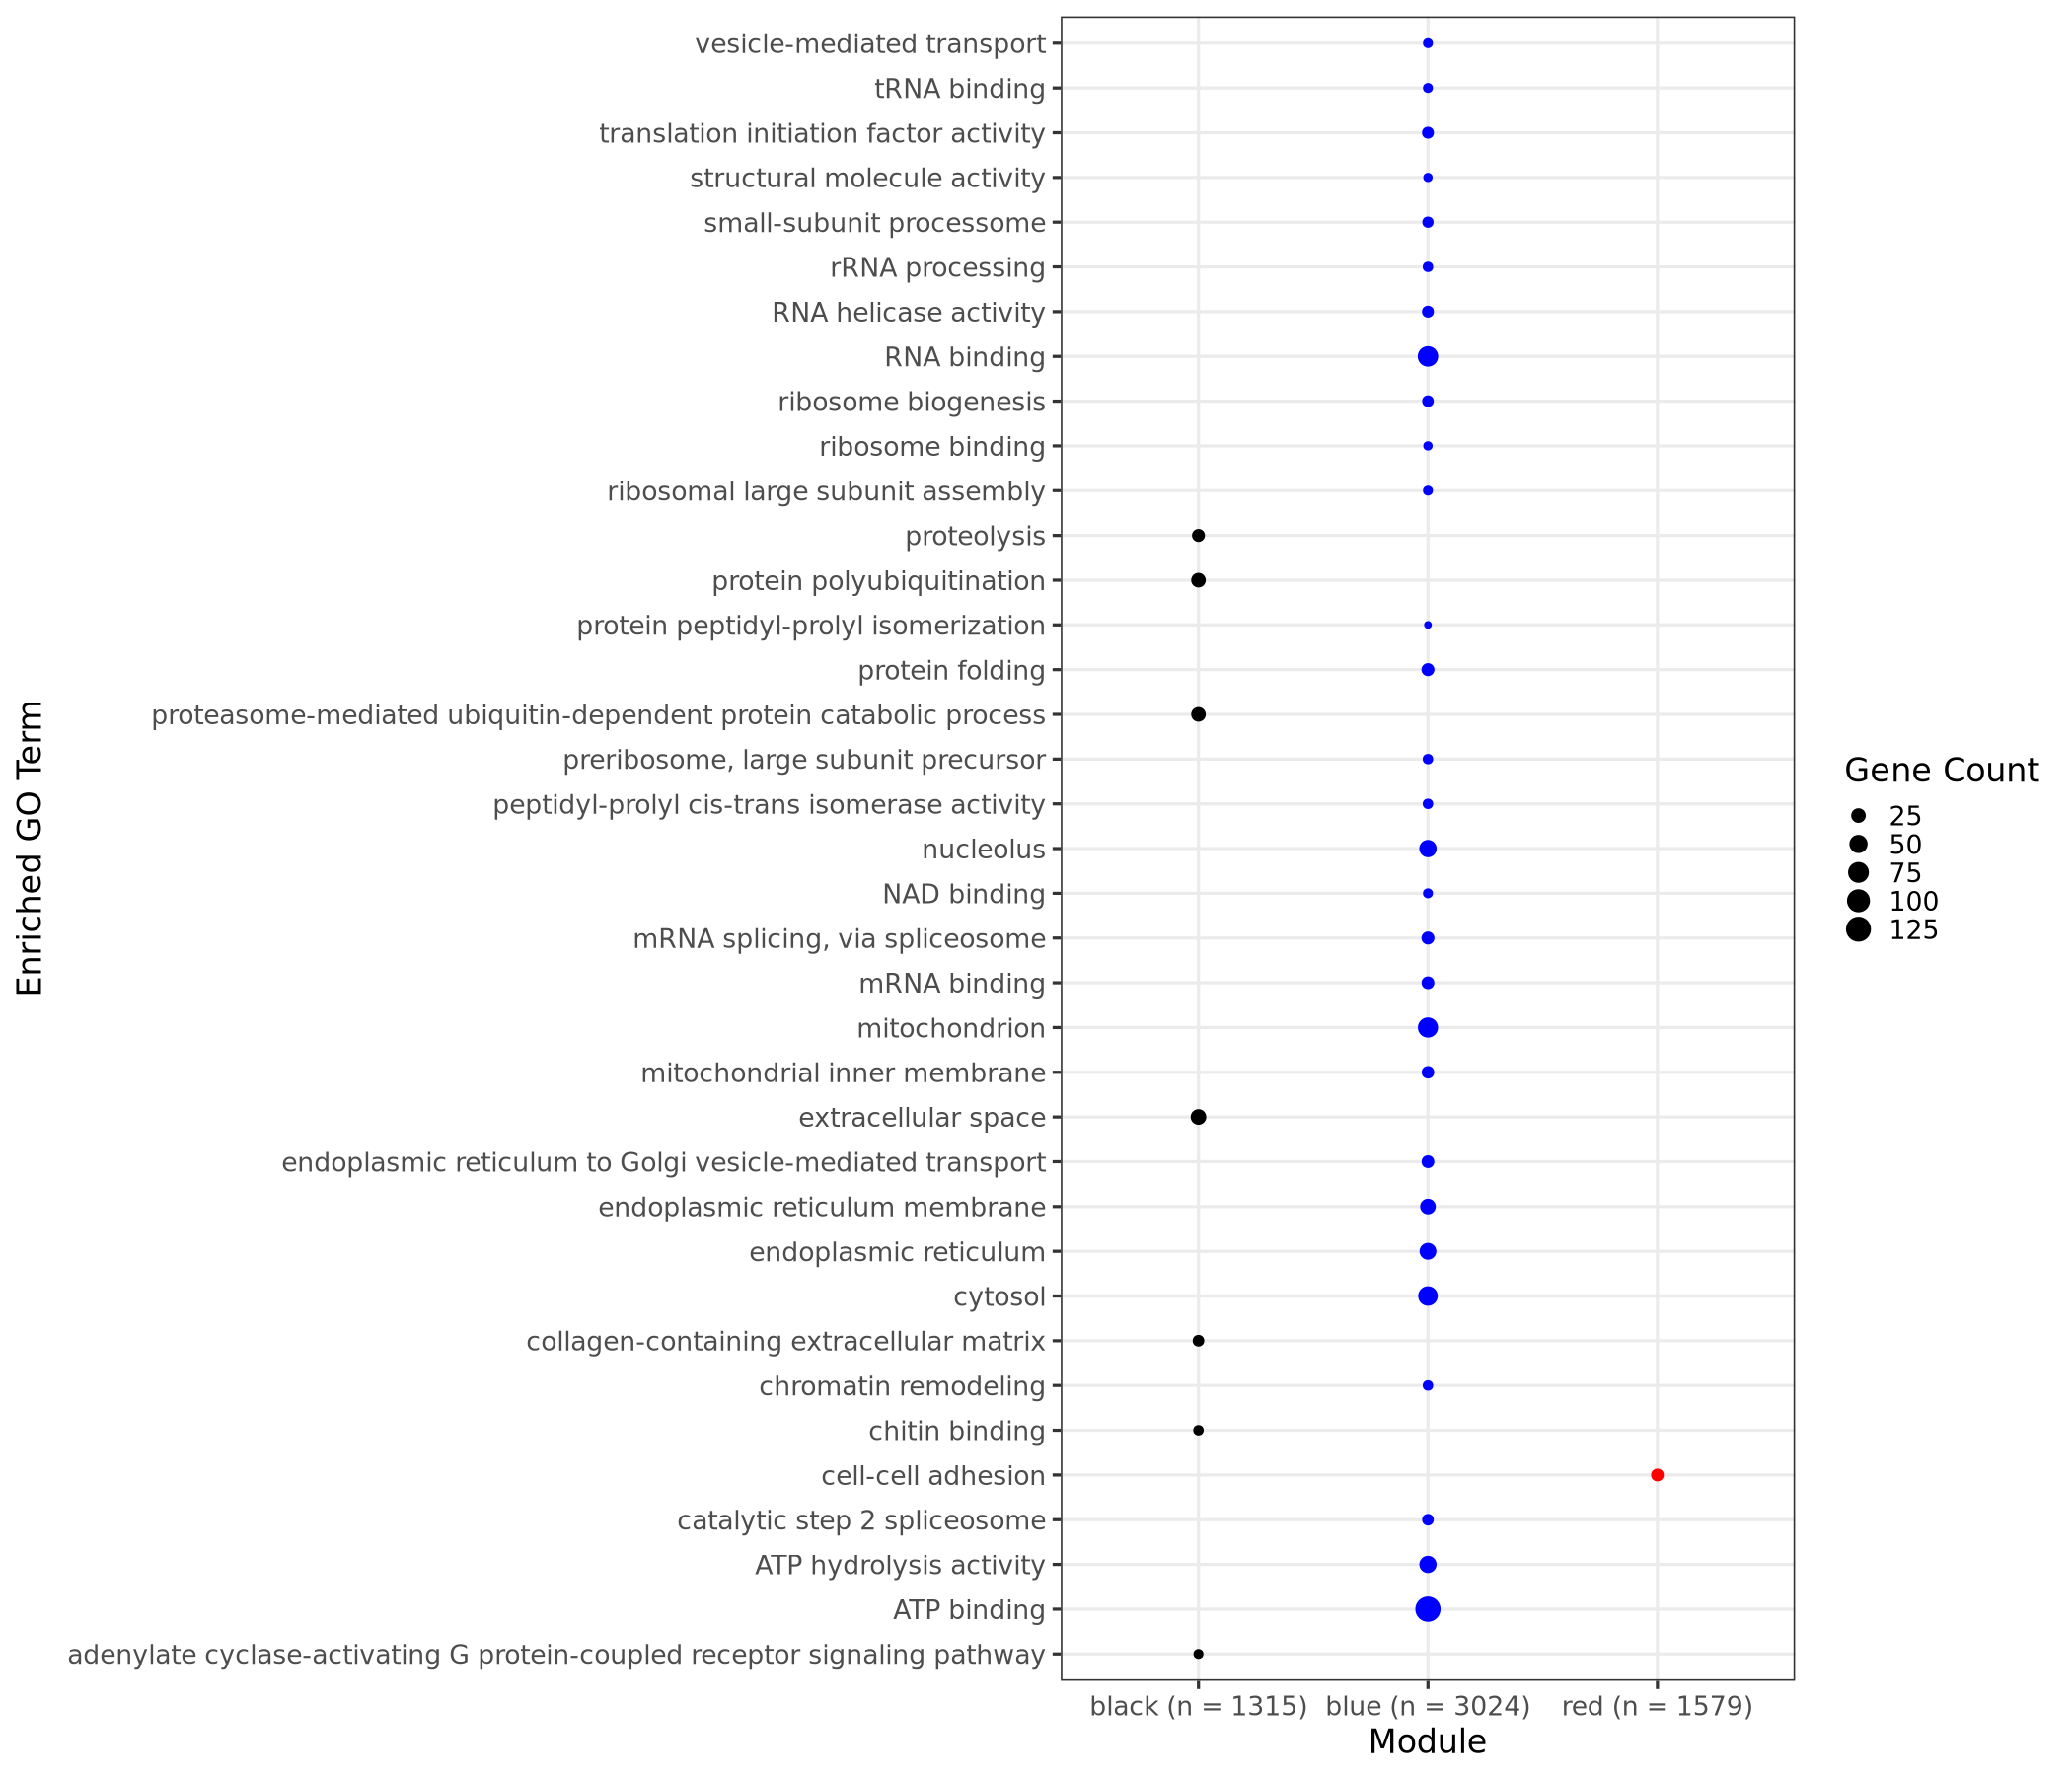

In [33]:
options(repr.plot.height = 15, repr.plot.width = 17.5)

module_gene_counts <- geneInfo %>%
  dplyr::count(ModuleColor)

module_labels <- setNames(
  paste0(module_gene_counts$ModuleColor, " (n = ", module_gene_counts$n, ")"),
  module_gene_counts$ModuleColor
)

ggplot(mod.all, aes(
  x = module,
  y = Description,
  size = Count,
  color = module
)) +
  guides(color = 'none') +
  scale_color_manual(values = c('black', 'blue', 'red')) +
  scale_x_discrete(labels = module_labels) +
  geom_point() +
  labs(
    x = "Module",
    y = "Enriched GO Term",
    size = "Gene Count"
  ) +
  theme_bw(base_size = 20)

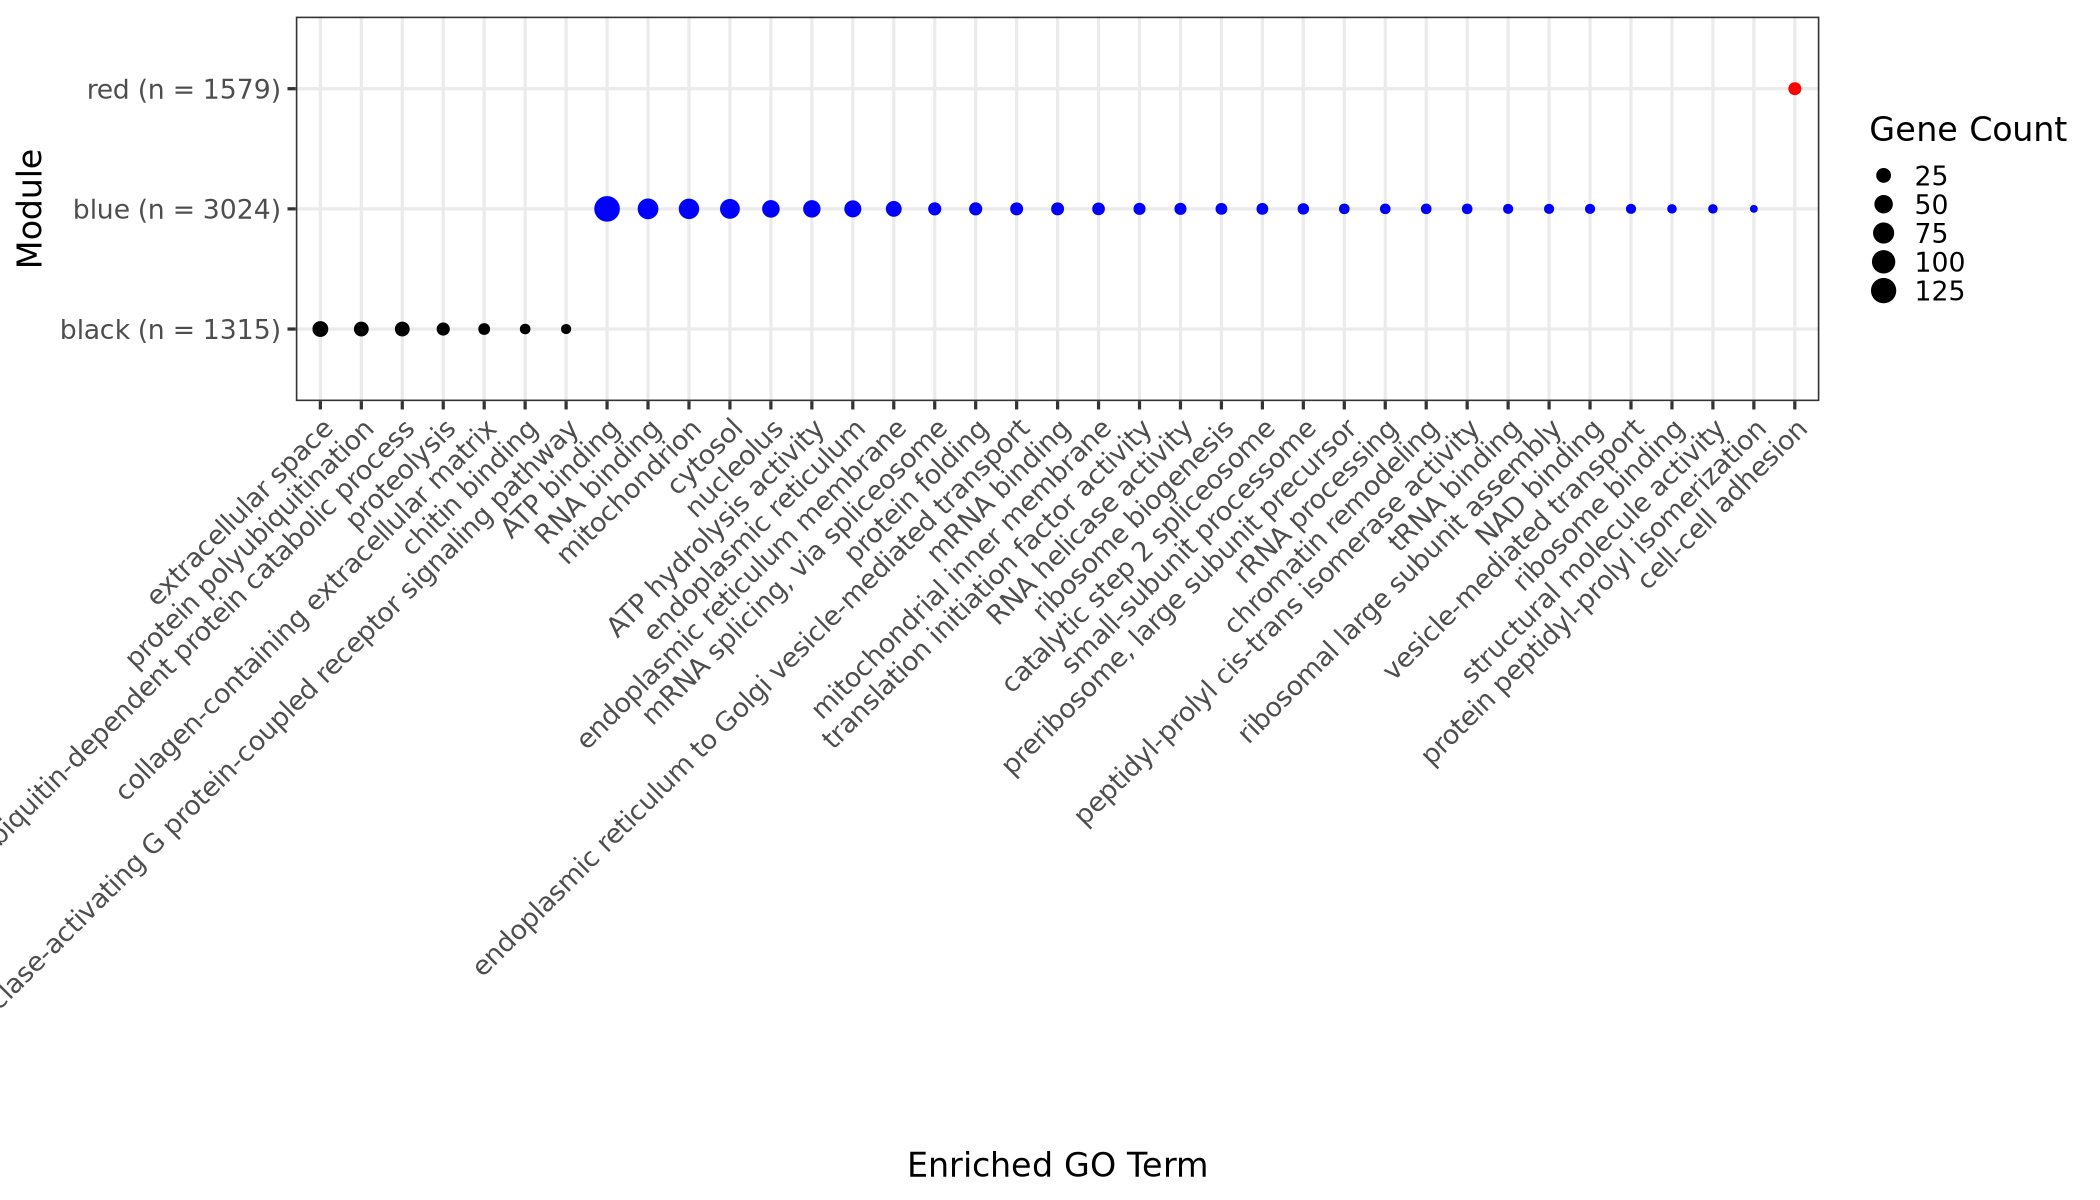

In [44]:
options(repr.plot.height = 10, repr.plot.width = 17.5)

# Order terms by module (and by Count within each module)
mod.all <- mod.all %>%
  mutate(module = factor(module, levels = c("black", "blue", "red"))) %>%  # set your preferred module order
  arrange(module, desc(Count)) %>%
  mutate(Description = factor(Description, levels = unique(Description)))

module_gene_counts <- geneInfo %>%
  dplyr::count(ModuleColor)

module_labels <- setNames(
  paste0(module_gene_counts$ModuleColor, " (n = ", module_gene_counts$n, ")"),
  module_gene_counts$ModuleColor
)

ggplot(mod.all, aes(
  x = module,
  y = Description,
  size = Count,
  color = module
)) +
  guides(color = 'none') +
  scale_color_manual(values = c('black', 'blue', 'red')) +
  scale_x_discrete(labels = module_labels) +
  geom_point() +
  labs(
    x = "Module",
    y = "Enriched GO Term",
    size = "Gene Count"
  ) +
  coord_flip() +
  theme_bw(base_size = 20) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1))

### adding GOslim

In [34]:
mod.mapped <- mod.all %>%
  # Process each row's ID individually
  rowwise() %>%
  # use function from earlier to map parent term to GO ID
  mutate(SlimID = find_slim_parent(ID, target_slim_ids)) %>% 
  ungroup() %>%
  # Join with lookup table to get 'GOSlim_Bin'
  left_join(slim_lookup, by = "SlimID")

# Remove terms that didn't map to a slim category if desired
mod.slim <- mod.mapped %>%
  filter(!is.na(GOSlim_Bin))

head(mod.slim)

ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,module,SlimID,GOSlim_Bin
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>
GO:0005730,nucleolus,0.032403919,51/7744,9.906095e-26,3.130326e-23,2.731997e-23,LOC111103620/LOC111103629/LOC111104266/LOC111104419/LOC111105256/LOC111103978/LOC111125438/LOC111123381/LOC111113203/LOC111099808/LOC111127822/LOC111132803/LOC111105066/LOC111118739/LOC111110332/LOC111136243/LOC111133059/LOC111135974/LOC111133926/LOC144626880/LOC111136414/LOC111135538/LOC111135726/LOC111134594/LOC111138243/LOC111135552/LOC111136220/LOC111133335/LOC111135565/LOC111135336/LOC111132132/LOC111134754/LOC111129891/LOC111130503/LOC111127734/LOC111130371/LOC111120892/LOC111121751/LOC111121130/LOC111118852/LOC111120775/LOC111118069/LOC111112939,43,blue,GO:0005730,nucleolus
GO:0003723,RNA binding,0.053504145,165/7744,2.950963e-15,4.662522e-13,4.069223e-13,LOC144622099/LOC111105256/LOC144623848/LOC111104149/LOC111099922/LOC144617720/LOC144618962/LOC144618954/LOC144619035/LOC111123381/LOC144622290/LOC111127420/LOC111126771/LOC111125036/LOC111111061/LOC111113059/LOC111118963/LOC144625294/LOC111116966/LOC144625443/LOC111107584/LOC111118739/LOC111113115/LOC144625869/LOC111136243/LOC111133148/LOC111133159/LOC111133163/LOC144626230/LOC111134482/LOC111135736/LOC111138309/LOC111133458/LOC111138363/LOC111134942/LOC111136413/LOC111135391/LOC111134872/LOC111105686/LOC111105897/LOC144617766/LOC144618451/LOC111136164/LOC111136320/LOC111136408/LOC111135336/LOC111100592/LOC111129496/LOC111130925/LOC111129950/LOC111130503/LOC111128922/LOC111128711/LOC111128022/LOC111129406/LOC111118055/LOC111118362/LOC111121372/LOC111118140/LOC111121238/LOC111118852/LOC111118340/LOC111119023/LOC111118356/LOC111118049/LOC111120899/LOC111120863/LOC111119055/LOC111118069/LOC111118539/LOC111112550,71,blue,GO:0003723,RNA binding
GO:0005739,mitochondrion,0.051243406,189/7744,2.337274e-10,2.461929e-08,2.148652e-08,LOC111103557/LOC111104353/LOC111103813/LOC111104483/LOC111107779/LOC111100670/LOC111125126/LOC144622705/LOC144622927/LOC144625154/LOC111119097/LOC111127947/LOC111121154/LOC111105388/LOC111114229/LOC111130095/LOC144626864/LOC111134378/LOC111133041/LOC111133507/LOC111136015/LOC111133477/LOC111134852/LOC111135733/LOC111132172/LOC111133426/LOC111138406/LOC111107699/LOC111105692/LOC111110422/LOC144627595/LOC111105866/LOC111107126/LOC111136221/LOC111133074/LOC111135530/LOC111133661/LOC111100599/LOC111099882/LOC111100042/LOC111128270/LOC111130738/LOC111130742/LOC111129316/LOC111127785/LOC111129893/LOC111129959/LOC111128042/LOC111128260/LOC111128143/LOC111130538/LOC111129859/LOC111128617/LOC111130025/LOC111130718/LOC111130667/LOC111128646/LOC111130282/LOC111128302/LOC111121506/LOC111117758/LOC111118224/LOC111120899/LOC111118028/LOC111118249/LOC111114527/LOC111115725/LOC111114537,68,blue,GO:0005739,mitochondrion
GO:0005783,endoplasmic reticulum,0.029389601,85/7744,5.831838e-10,4.607152e-08,4.020899e-08,LOC111103667/LOC111103374/LOC111104256/LOC111104398/LOC111099696/LOC111125385/LOC111125459/LOC111127278/LOC111125076/LOC111104099/LOC111107354/LOC111136404/LOC111132171/LOC111134266/LOC111106990/LOC111136327/LOC111133811/LOC111138014/LOC111117721/LOC111136083/LOC111133834/LOC111133475/LOC111133739/LOC111106015/LOC111135553/LOC111134680/LOC111130055/LOC111130644/LOC111128101/LOC111127779/LOC111130781/LOC111128545/LOC111128205/LOC111118233/LOC111121532/LOC111121436/LOC111117746/LOC111118249/LOC111121482,39,blue,GO:0005783,endoplasmic reticulum
GO:0000398,"mRNA splicing, via spliceosome",0.012810852,25/7744,2.334958e-08,1.054067e-06,9.199385e-07,LOC111104149/LOC111099922/LOC144622290/LOC111125036/LOC111111061/LOC111135499/LOC111138391/LOC111138363/LOC111133954/LOC111106208/LOC111107428/LOC111136320/LOC111136408/LOC111118194/LOC111121238/LOC111119018/LOC111119055,17,blue,GO:0016071,mRNA metabolic process
GO:0042254,ribosome biogenesis,0.009042954,16/7744,5.659766e-07,1.625896e-05,1.419004e-05,LOC111133059/LOC111134348/LOC11

### Module-Trait GO Enrichment

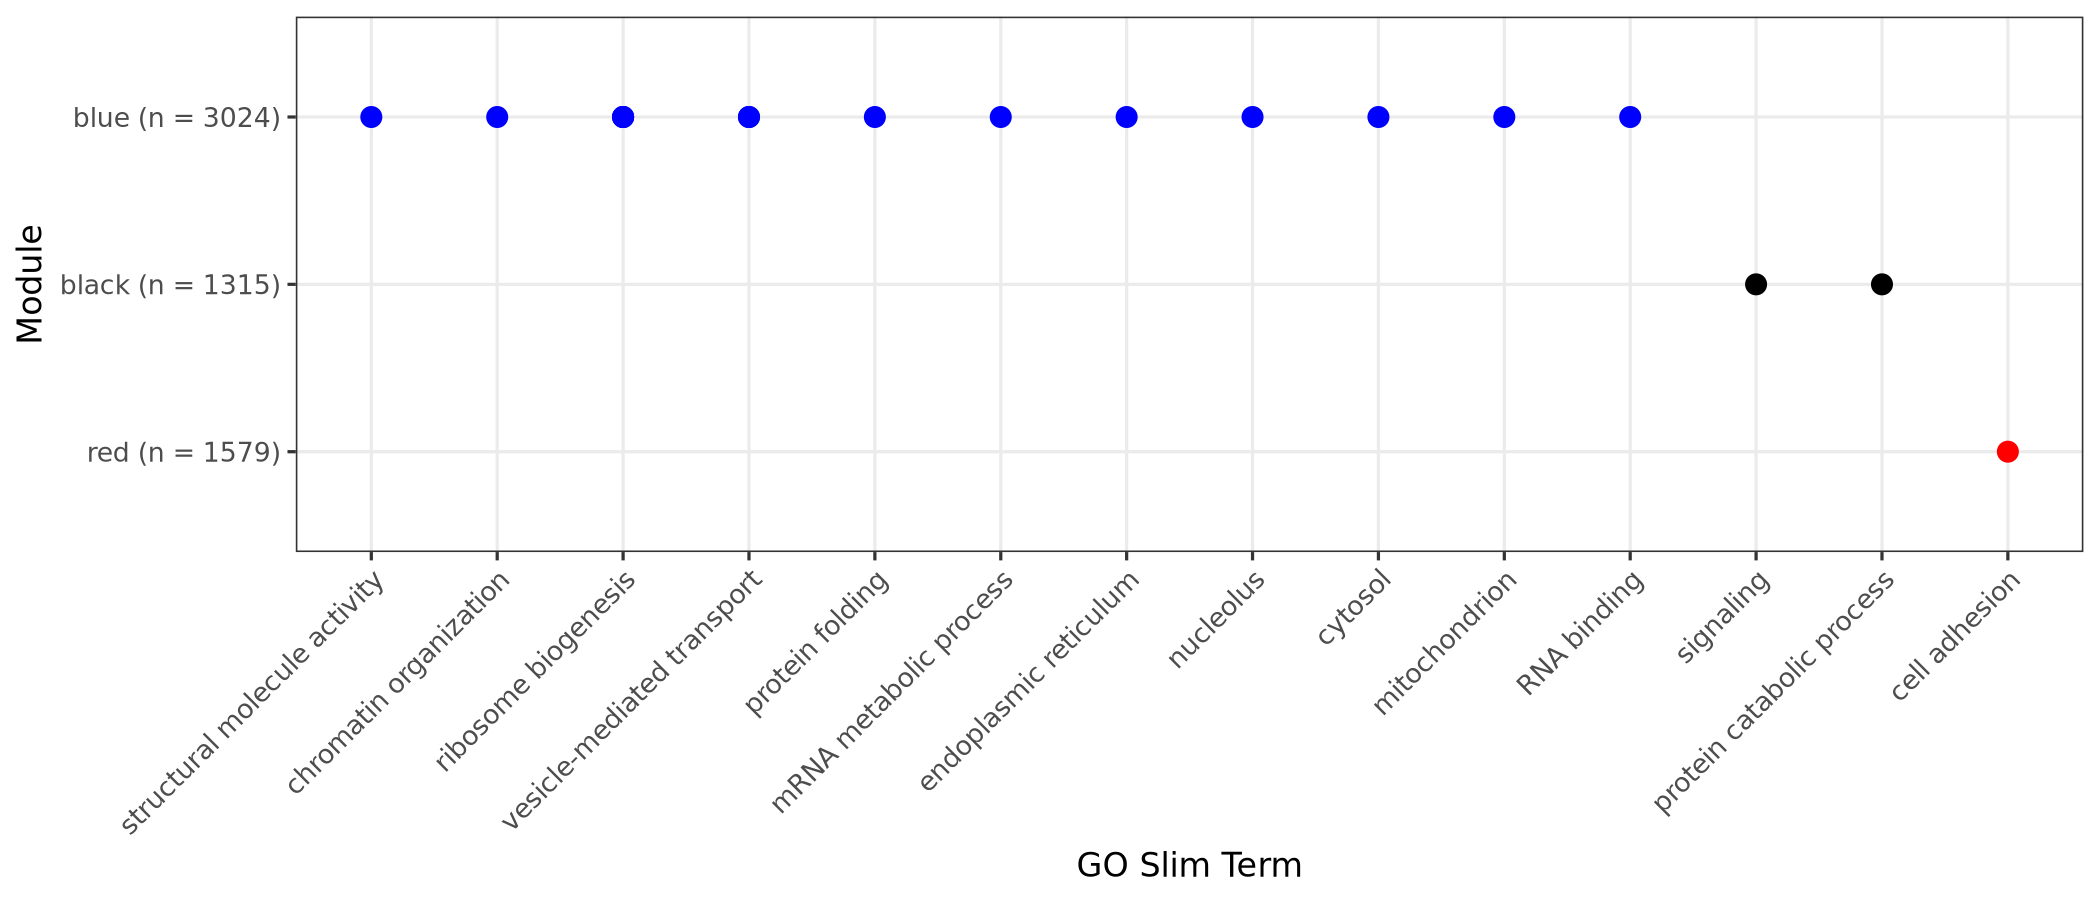

In [35]:
options(repr.plot.height = 7.5, repr.plot.width = 17.5)


# 1. set explicit module order
module_order <- c("red", "black", "blue")   # put them in whatever order you want

mod.slim <- mod.slim %>%
  mutate(module = factor(module, levels = module_order))

# 2. order GOSlim_Bin by each bin's most significant module (respecting module_order for ties)
bin_order <- mod.slim %>%
  group_by(GOSlim_Bin) %>%
  slice_min(p.adjust, n = 1, with_ties = FALSE) %>%
  arrange(module, desc(Count)) %>%
  pull(GOSlim_Bin) %>%
  unique()

mod.slim2 <- mod.slim %>%
  mutate(GOSlim_Bin = factor(GOSlim_Bin, levels = rev(bin_order)))

# 3. update module_labels to match the new factor order (if not already matching)
module_labels <- module_labels[module_order]

ggplot(mod.slim2, aes(
  x = module,
  y = GOSlim_Bin,
  color = module
)) +
  guides(color = 'none') +
  scale_color_manual(values = c('red', 'black', 'blue'), drop = FALSE) +
  scale_x_discrete(labels = module_labels) +
  geom_point(size = 5) +
  labs(
    x = "Module",
    y = "GO Slim Term"
  ) +
  coord_flip() +
  theme_bw(base_size = 20) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

# I STOPPED HERE
## 3. Deeper dive

### blue module
Running ORA enrichment on growth vs. warm associated genes in the blue module

for this, I'm going to keep the universal list as all those that went into the WGCNA model

In [37]:
blueModGenes <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/wgcna/outputs/moduleGenes/blueModGenes.csv')
head(blueModGenes)

,Gene,GO.terms,ModuleColor,GS.Actual_shell_growth_mg,GS.warm,p.GS.GS.Actual_shell_growth_mg,p.GS.GS.warm,geneClass
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,LOC111099029,GO:0005261;GO:0005886;GO:0030001;GO:0098655,blue,0.39966747,0.31929640,0.05882963,0.137519691,Neither
2,LOC111099039,GO:0004930;GO:0005886;GO:0007189,blue,0.44340350,0.29305474,0.03407378,0.174755141,Growth
3,LOC111099053,GO:0001731;GO:0003729;GO:0003743;GO:0005850;GO:0006413;GO:0031369,blue,0.43025668,0.51665255,0.04043220,0.011597196,Both
4,LOC111099056,GO:0003723;GO:0006396;GO:0008173,blue,0.04069859,0.05234405,0.85371948,0.812504555,Neither
5,LOC111099067,GO:0000463;GO:0005634;GO:0008650;GO:0030687;GO:0031167,blue,0.33300808,0.38777609,0.12049730,0.067505091,Neither
6,LOC111099690,GO:0009226;GO:0050577,blue,0.46954235,0.53354451,0.02378955,0.008743777,Both


#### growth associated genes

In [36]:
blue_growth <- blueModGenes %>% filter(geneClass == 'Growth') %>% pull(Gene)
length(blue_growth)

ERROR: Error: object 'blueModGenes' not found


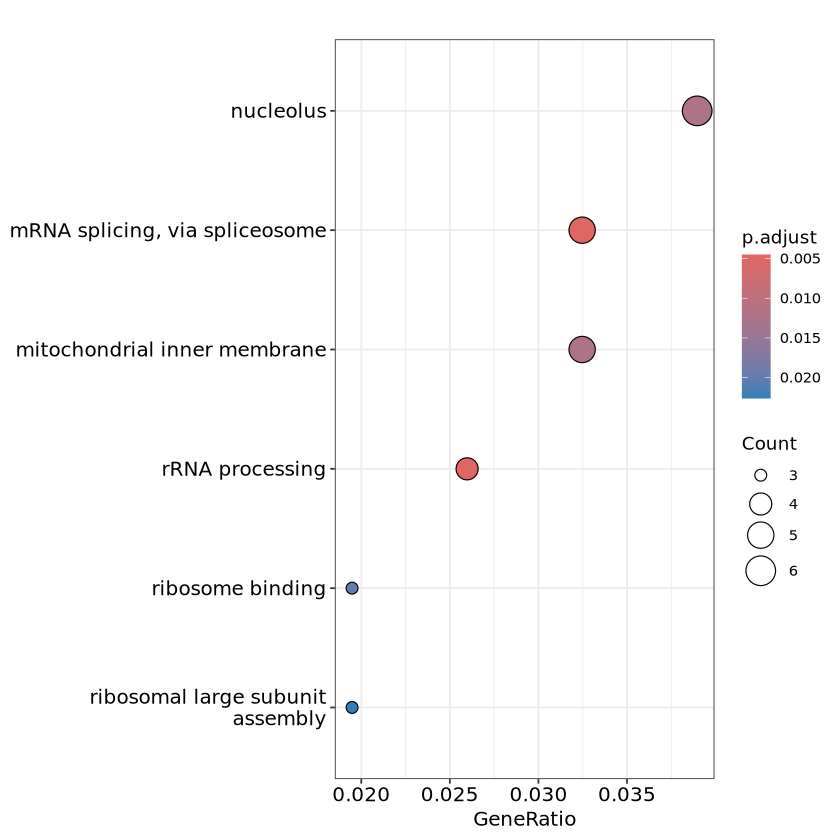

In [18]:
# Run the custom enrichment
ego_custom <- enricher(gene = blue_growth,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
growth_res <- as.data.frame(ego_custom)

# View results
dotplot(ego_custom)

#### warm associated genes

In [19]:
blue_warm <- blueModGenes %>% filter(geneClass == 'Warm') %>% pull(Gene)
length(blue_warm)

[1] 167

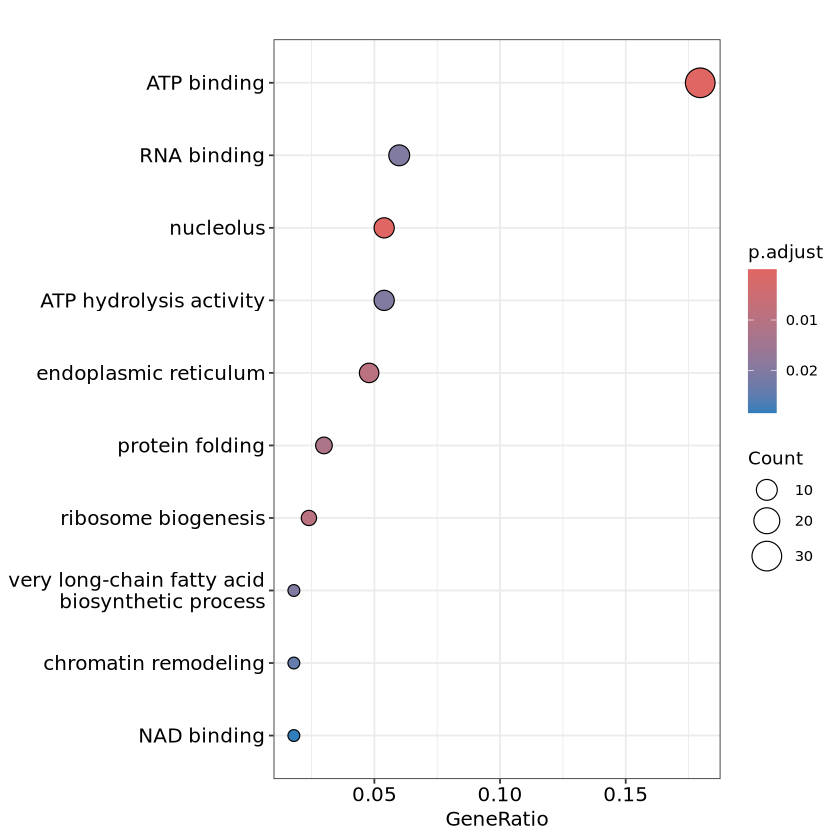

In [20]:
# Run the custom enrichment
ego_custom <- enricher(gene = blue_warm,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
warm_res <- as.data.frame(ego_custom)

# View results
dotplot(ego_custom)

#### both growth and warm associated genes

In [21]:
blue_both <- blueModGenes %>% filter(geneClass == 'Both') %>% pull(Gene)
length(blue_both)

[1] 111

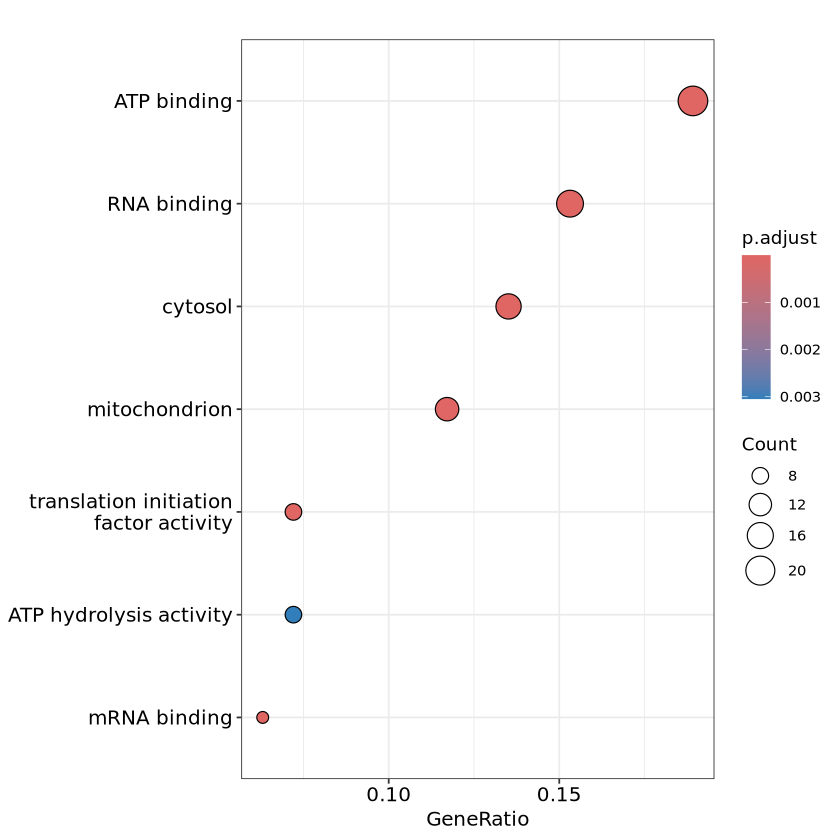

In [22]:
# Run the custom enrichment
ego_custom <- enricher(gene = blue_both,
                       universe = universal_genes$gene,
                       TERM2NAME = term2name,
                       TERM2GENE = term2gene,
                       pvalueCutoff = 0.05)

# make df
both_res <- as.data.frame(ego_custom)

# View results
dotplot(ego_custom)